# Daraz Product Analysis — Modular Final Project

**Datasource:** `Watches Bags Accessories.csv`  
**Rule followed:** every module works with the real Daraz datasource or a cleaned file generated directly from it.

This notebook is the main program. It creates the Python modules with `%%writefile`, imports them, and then uses those modules to complete the analysis.

## Project architecture

| Module | Course concept / responsibility |
|---|---|
| `module01_variables.py` | Variables and data types |
| `module02_loops.py` | `for` loops |
| `module03_conditions.py` | `if / elif / else` |
| `module04_functions.py` | Functions, parameters and return values |
| `module05_cleaning.py` | Data cleaning and file output |
| `module06_pandas_analysis.py` | Pandas analysis |
| `module07_numpy_analysis.py` | NumPy numerical analysis |
| `module08_visualization.py` | Matplotlib visualization |
| `module09_findings.py` | Findings and limitations |

The modules are separated for modular programming, but they remain connected through the same real datasource.

## Part 1: Create `module01_variables.py`

The following cell writes a reusable Python module. Its functions operate on the real Daraz datasource.

In [47]:
%%writefile module01_variables.py
"""Module 01: Variables and data types using the real Daraz datasource only."""

import pandas as pd


def inspect_variables(csv_path):
    """Read the real datasource and return variables that describe it."""
    df = pd.read_csv(csv_path)

    row_count = df.shape[0]
    column_count = df.shape[1]
    column_names = df.columns.tolist()
    category_count = df["Category"].nunique(dropna=True)
    categories = df["Category"].dropna().unique().tolist()
    data_types = df.dtypes.astype(str).to_dict()
    first_real_title = df.loc[df.index[0], "Title"] if len(df) else None

    return {
        "row_count": row_count,
        "column_count": column_count,
        "column_names": column_names,
        "category_count": category_count,
        "categories": categories,
        "data_types": data_types,
        "first_real_title": first_real_title,
    }


Overwriting module01_variables.py


## Part 2: Create `module02_loops.py`

The following cell writes a reusable Python module. Its functions operate on the real Daraz datasource.

In [48]:
%%writefile module02_loops.py
"""Module 02: Loops applied to the real Daraz datasource only."""

import pandas as pd


def category_counts_with_loop(csv_path):
    """Count actual Daraz categories using a for loop instead of value_counts()."""
    df = pd.read_csv(csv_path)
    counts = {}

    for category in df["Category"].dropna():
        if category in counts:
            counts[category] += 1
        else:
            counts[category] = 1

    return dict(sorted(counts.items(), key=lambda item: item[1], reverse=True))


def missing_values_with_loop(csv_path):
    """Count missing values column-by-column using a loop on the real data."""
    df = pd.read_csv(csv_path)
    missing = {}

    for column in df.columns:
        missing[column] = int(df[column].isna().sum())

    return missing


Overwriting module02_loops.py


## Part 3: Create `module03_conditions.py`

The following cell writes a reusable Python module. Its functions operate on the real Daraz datasource.

In [49]:
%%writefile module03_conditions.py
"""Module 03: Conditional logic applied to real Daraz values only."""

import pandas as pd


def price_group(price):
    """Classify an actual cleaned Daraz price using if/elif/else."""
    if pd.isna(price):
        return "Unknown"
    if price < 500:
        return "Budget"
    elif price < 2000:
        return "Mid"
    else:
        return "Expensive"


def delivery_label(value):
    """Translate the datasource's delivery code into a readable label."""
    if str(value) == "0":
        return "No Free Delivery"
    else:
        return str(value)


def voucher_label(value):
    """Reduce the real voucher field to a Yes/No feature."""
    if str(value) == "0":
        return "No"
    else:
        return "Yes"


def condition_summary(csv_path):
    """Apply conditional rules to the actual datasource and summarize the results."""
    df = pd.read_csv(csv_path)
    prices = pd.to_numeric(df["Current Price"].astype(str).str.replace(",", "", regex=False), errors="coerce")

    price_groups = {"Budget": 0, "Mid": 0, "Expensive": 0, "Unknown": 0}
    for price in prices:
        group = price_group(price)
        price_groups[group] += 1

    delivery_groups = {"Free Delivery": 0, "No Free Delivery": 0}
    for value in df["Delivery"]:
        label = delivery_label(value)
        if label in delivery_groups:
            delivery_groups[label] += 1

    voucher_groups = {"Yes": 0, "No": 0}
    for value in df["Voucher"]:
        voucher_groups[voucher_label(value)] += 1

    return {
        "price_groups_raw_rows": price_groups,
        "delivery_groups_raw_rows": delivery_groups,
        "voucher_groups_raw_rows": voucher_groups,
    }


Overwriting module03_conditions.py


## Part 4: Create `module04_functions.py`

The following cell writes a reusable Python module. Its functions operate on the real Daraz datasource.

In [50]:
%%writefile module04_functions.py
"""Module 04: Reusable functions for cleaning real Daraz fields."""

import pandas as pd


def clean_current_price(value):
    """Convert a Current Price value from the datasource to numeric."""
    if pd.isna(value):
        return None
    return pd.to_numeric(str(value).replace(",", ""), errors="coerce")


def clean_original_price(value):
    """Remove Rs. and commas from Original Price and convert to numeric."""
    if pd.isna(value):
        return None
    text = str(value).replace("Rs. ", "").replace(",", "")
    return pd.to_numeric(text, errors="coerce")


def clean_rating(value, rating_count):
    """Convert '4.6/5' to 4.6; unrated products become missing, not 0-star."""
    if pd.isna(value):
        return None
    rating = pd.to_numeric(str(value).replace("/5", ""), errors="coerce")
    if rating_count == 0:
        return None
    return rating


def sold_to_number(value):
    """Convert values such as '6K Sold' to 6000 using real datasource formatting."""
    if pd.isna(value):
        return None

    text = str(value).replace(" Sold", "").strip()
    if "K" in text:
        return float(text.replace("K", "")) * 1000
    else:
        return float(text)


def calculate_discount(original_price, current_price):
    """Return discount amount and percentage from real cleaned prices."""
    if pd.isna(original_price) or pd.isna(current_price) or original_price == 0:
        return None, None
    discount = original_price - current_price
    discount_percent = (discount / original_price) * 100
    return discount, discount_percent


def function_preview(csv_path, n=5):
    """Apply the reusable functions to the first n REAL rows from the datasource."""
    df = pd.read_csv(csv_path).head(n).copy()
    preview = pd.DataFrame({
        "Raw Current Price": df["Current Price"],
        "Clean Current Price": df["Current Price"].apply(clean_current_price),
        "Raw Sold Count": df["Sold Count"],
        "Clean Sold Count": df["Sold Count"].apply(sold_to_number),
        "Raw Rating": df["Rating in Stars"],
        "Clean Rating": [clean_rating(v, c) for v, c in zip(df["Rating in Stars"], df["Rating Count"])],
    })
    return preview


Overwriting module04_functions.py


## Part 5: Create `module05_cleaning.py`

The following cell writes a reusable Python module. Its functions operate on the real Daraz datasource.

In [51]:
%%writefile module05_cleaning.py
"""Module 05: Data cleaning pipeline for the real Daraz datasource."""

import pandas as pd
from module03_conditions import delivery_label, voucher_label
from module04_functions import (
    clean_current_price,
    clean_original_price,
    clean_rating,
    sold_to_number,
    calculate_discount,
)


def clean_dataset(csv_path, output_path="daraz_cleaned_data.csv"):
    """Clean the actual Daraz CSV and save a reusable cleaned datasource."""
    df = pd.read_csv(csv_path)
    raw_rows = len(df)
    exact_duplicates = int(df.duplicated().sum())
    repeated_links = int(df.duplicated(subset=["Link"]).sum())

    # Link is the best product identifier in this datasource.
    df = df.drop_duplicates(subset=["Link"], keep="first").copy()

    # Use reusable functions on real datasource columns.
    df["Current Price"] = df["Current Price"].apply(clean_current_price)
    df["Original Price"] = df["Original Price"].apply(clean_original_price)
    df["Rating in Stars"] = [
        clean_rating(value, count)
        for value, count in zip(df["Rating in Stars"], df["Rating Count"])
    ]

    sold_numbers = []
    for value in df["Sold Count"]:
        sold_numbers.append(sold_to_number(value))
    df["Sold Count"] = sold_numbers

    df["Delivery"] = df["Delivery"].apply(delivery_label)
    df["Has Voucher"] = df["Voucher"].apply(voucher_label)

    discounts = []
    discount_percents = []
    for original, current in zip(df["Original Price"], df["Current Price"]):
        amount, percent = calculate_discount(original, current)
        discounts.append(amount)
        discount_percents.append(percent)
    df["Discount"] = discounts
    df["Discount %"] = discount_percents

    # Drop fields not needed after identification and cleaning.
    df = df.drop(columns=["Voucher", "Currency", "Link"])

    df.to_csv(output_path, index=False)

    report = {
        "raw_rows": raw_rows,
        "exact_duplicate_rows": exact_duplicates,
        "repeated_product_links": repeated_links,
        "cleaned_rows": len(df),
        "cleaned_columns": df.shape[1],
        "original_price_below_current": int((df["Original Price"] < df["Current Price"]).sum()),
        "missing_values": df.isna().sum().to_dict(),
        "output_path": output_path,
    }
    return df, report


Overwriting module05_cleaning.py


## Part 6: Create `module06_pandas_analysis.py`

The following cell writes a reusable Python module. Its functions operate on the real Daraz datasource.

In [52]:
%%writefile module06_pandas_analysis.py
"""Module 06: Pandas analysis using the cleaned real Daraz datasource."""

import pandas as pd
from module03_conditions import price_group


def run_pandas_analysis(cleaned_csv_path, analysis_output_path="daraz_analysis_ready.csv"):
    """Answer the main project questions with pandas on real cleaned data."""
    df = pd.read_csv(cleaned_csv_path)

    # Apply a real classification rule to every cleaned product price.
    groups = []
    for price in df["Current Price"]:
        groups.append(price_group(price))
    df["Price Group"] = groups

    category_counts = df["Category"].value_counts()
    category_summary = df.groupby("Category").agg(
        products=("Title", "count"),
        median_price=("Current Price", "median"),
        median_sold=("Sold Count", "median"),
        average_rating=("Rating in Stars", "mean"),
        median_rating_count=("Rating Count", "median"),
        median_discount_pct=("Discount %", "median"),
    ).round(2)

    delivery_summary = df.groupby("Delivery")[["Current Price", "Sold Count", "Rating in Stars"]].median()
    voucher_summary = df.groupby("Has Voucher")[["Current Price", "Sold Count", "Rating in Stars"]].median()
    price_group_summary = df.groupby("Price Group")[["Sold Count", "Rating in Stars"]].median()

    top_sold = df.nlargest(5, "Sold Count")[[
        "Title", "Category", "Sold Count", "Current Price", "Rating in Stars", "Rating Count"
    ]]

    overall = {
        "cheapest_price": float(df["Current Price"].min()),
        "most_expensive_price": float(df["Current Price"].max()),
        "mean_price": float(df["Current Price"].mean()),
        "median_price": float(df["Current Price"].median()),
        "available_sold_count_sum": int(df["Sold Count"].sum()),
        "products_with_no_customer_rating": int((df["Rating Count"] == 0).sum()),
    }

    df.to_csv(analysis_output_path, index=False)

    return {
        "data": df,
        "category_counts": category_counts,
        "category_summary": category_summary,
        "delivery_summary": delivery_summary,
        "voucher_summary": voucher_summary,
        "price_group_summary": price_group_summary,
        "top_sold": top_sold,
        "overall": overall,
        "analysis_output_path": analysis_output_path,
    }


Overwriting module06_pandas_analysis.py


## Part 7: Create `module07_numpy_analysis.py`

The following cell writes a reusable Python module. Its functions operate on the real Daraz datasource.

In [53]:
%%writefile module07_numpy_analysis.py
"""Module 07: NumPy statistics and relationship analysis on real Daraz data."""

import pandas as pd
import numpy as np


def run_numpy_analysis(cleaned_csv_path):
    """Use NumPy arrays, percentiles, IQR, boolean comparisons and correlation."""
    df = pd.read_csv(cleaned_csv_path)

    sold_array = df["Sold Count"].dropna().to_numpy(dtype=float)
    q1, median, q3 = np.percentile(sold_array, [25, 50, 75])
    iqr = q3 - q1
    upper_iqr_threshold = q3 + 1.5 * iqr
    above_threshold = int(np.sum(sold_array > upper_iqr_threshold))

    rating_sales = df[["Rating Count", "Sold Count"]].dropna()
    rating_count_array = rating_sales["Rating Count"].to_numpy(dtype=float)
    sold_count_array = rating_sales["Sold Count"].to_numpy(dtype=float)
    rating_sales_corr = float(np.corrcoef(rating_count_array, sold_count_array)[0, 1])

    # Keep the wider relationship table for interpretation.
    relationship_corr = df[[
        "Current Price", "Rating in Stars", "Rating Count", "Discount %", "Sold Count"
    ]].corr()["Sold Count"].drop("Sold Count").sort_values(ascending=False)

    return {
        "available_sold_records": int(sold_array.size),
        "q1": float(q1),
        "median": float(median),
        "q3": float(q3),
        "iqr": float(iqr),
        "upper_iqr_threshold": float(upper_iqr_threshold),
        "records_above_threshold": above_threshold,
        "numpy_rating_count_vs_sold_corr": rating_sales_corr,
        "relationship_correlations": relationship_corr,
    }


Overwriting module07_numpy_analysis.py


## Part 8: Create `module08_visualization.py`

The following cell writes a reusable Python module. Its functions operate on the real Daraz datasource.

In [54]:
%%writefile module08_visualization.py
"""Module 08: Matplotlib visualizations created only from real Daraz data."""

import pandas as pd
import matplotlib.pyplot as plt
from module03_conditions import price_group


def _load_analysis_data(cleaned_csv_path):
    df = pd.read_csv(cleaned_csv_path)
    if "Price Group" not in df.columns:
        df["Price Group"] = [price_group(price) for price in df["Current Price"]]
    return df


def plot_category_overview(cleaned_csv_path):
    df = _load_analysis_data(cleaned_csv_path)

    counts = df["Category"].value_counts()
    plt.figure(figsize=(10, 6))
    plt.bar(counts.index, counts.values, edgecolor="white", width=0.7)
    plt.title("Number of Products in Each Category")
    plt.xlabel("Category")
    plt.ylabel("Number of Products")
    plt.xticks(rotation=30, ha="right")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

    prices = df.groupby("Category")["Current Price"].median().sort_values()
    plt.figure(figsize=(10, 6))
    plt.barh(prices.index, prices.values, edgecolor="white")
    plt.title("Median Current Price by Category")
    plt.xlabel("Median Current Price (Rs)")
    plt.ylabel("Category")
    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()


def plot_price_distribution(cleaned_csv_path):
    df = _load_analysis_data(cleaned_csv_path)

    groups = df["Price Group"].value_counts()
    plt.figure(figsize=(7, 7))
    plt.pie(groups.values, labels=groups.index, autopct="%1.1f%%", explode=[0.05] + [0] * (len(groups) - 1))
    plt.title("Share of Products in Each Price Group")
    plt.show()

    plt.figure(figsize=(10, 5))
    plt.hist(df["Current Price"], bins=40, edgecolor="white")
    plt.title("Price Distribution of All Products")
    plt.xlabel("Price in Rs")
    plt.ylabel("Number of Products")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()


def plot_sales_and_ratings(cleaned_csv_path):
    df = _load_analysis_data(cleaned_csv_path)

    sold = df.groupby("Category")["Sold Count"].median().sort_values()
    plt.figure(figsize=(10, 6))
    plt.barh(sold.index, sold.values, edgecolor="white")
    plt.title("Median Sold Count by Category")
    plt.xlabel("Median Reported Units Sold")
    plt.ylabel("Category")
    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()

    ratings = df.groupby("Category")["Rating in Stars"].mean().sort_values()
    plt.figure(figsize=(10, 6))
    plt.barh(ratings.index, ratings.values, edgecolor="white")
    plt.title("Average Star Rating by Category (Rated Products Only)")
    plt.xlabel("Rating out of 5")
    plt.ylabel("Category")
    plt.xlim(0, 5)
    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()


def plot_relationships(cleaned_csv_path):
    df = _load_analysis_data(cleaned_csv_path)

    relationships = [
        ("Current Price", "Price vs Sold Count", "Price in Rs"),
        ("Rating Count", "Rating Count vs Sold Count", "Number of Ratings"),
        ("Discount %", "Discount Percentage vs Sold Count", "Discount Percentage"),
    ]

    correlations = {}
    for x_column, title, xlabel in relationships:
        plot_data = df.dropna(subset=[x_column, "Sold Count"])
        plt.figure(figsize=(10, 6))
        plt.scatter(plot_data[x_column], plot_data["Sold Count"], alpha=0.45, edgecolor="white", linewidth=0.3)
        plt.title(title)
        plt.xlabel(xlabel)
        plt.ylabel("Reported Units Sold")
        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()
        correlations[x_column] = float(plot_data[x_column].corr(plot_data["Sold Count"]))

    return correlations


def plot_promotion_comparisons(cleaned_csv_path):
    df = _load_analysis_data(cleaned_csv_path)

    delivery = df.groupby("Delivery")["Sold Count"].median()
    voucher = df.groupby("Has Voucher")["Sold Count"].median()

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    ax1.bar(delivery.index, delivery.values, edgecolor="white")
    ax1.set_title("Median Sold Count by Free-Delivery Status")
    ax1.set_xlabel("Delivery Status")
    ax1.set_ylabel("Reported Units Sold")
    ax1.grid(axis="y", alpha=0.3)

    ax2.bar(voucher.index, voucher.values, edgecolor="white")
    ax2.set_title("Median Sold Count by Voucher Status")
    ax2.set_xlabel("Has Voucher")
    ax2.set_ylabel("Reported Units Sold")
    ax2.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

    voucher_by_category = df.pivot_table(
        index="Category", columns="Has Voucher", values="Sold Count", aggfunc="median"
    )
    voucher_counts = df.pivot_table(
        index="Category", columns="Has Voucher", values="Title", aggfunc="count", fill_value=0
    )

    voucher_by_category.plot(kind="bar", figsize=(11, 6), edgecolor="white")
    plt.title("Median Sold Count With and Without Vouchers, by Category")
    plt.xlabel("Category")
    plt.ylabel("Reported Units Sold")
    plt.xticks(rotation=30, ha="right")
    plt.legend(title="Has Voucher")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

    return voucher_counts


Overwriting module08_visualization.py


## Part 9: Create `module09_findings.py`

The following cell writes a reusable Python module. Its functions operate on the real Daraz datasource.

In [55]:
%%writefile module09_findings.py
"""Module 09: Final findings generated from the real Daraz datasource."""

import pandas as pd


def generate_findings(raw_csv_path, cleaned_csv_path):
    """Compute final project findings from the actual raw and cleaned files."""
    raw_df = pd.read_csv(raw_csv_path)
    df = pd.read_csv(cleaned_csv_path)

    category_price = df.groupby("Category")["Current Price"].median().sort_values(ascending=False)
    category_sales = df.groupby("Category")["Sold Count"].median().sort_values(ascending=False)

    correlations = df[[
        "Current Price", "Rating in Stars", "Rating Count", "Discount %", "Sold Count"
    ]].corr()["Sold Count"].drop("Sold Count")

    findings = {
        "raw_rows": int(len(raw_df)),
        "unique_product_rows": int(len(df)),
        "median_price": float(df["Current Price"].median()),
        "mean_price": float(df["Current Price"].mean()),
        "highest_median_price_category": category_price.index[0],
        "highest_median_price": float(category_price.iloc[0]),
        "highest_median_sold_category": category_sales.index[0],
        "highest_median_sold": float(category_sales.iloc[0]),
        "lowest_median_sold_category": category_sales.index[-1],
        "lowest_median_sold": float(category_sales.iloc[-1]),
        "price_sold_correlation": float(correlations["Current Price"]),
        "rating_sold_correlation": float(correlations["Rating in Stars"]),
        "rating_count_sold_correlation": float(correlations["Rating Count"]),
        "discount_sold_correlation": float(correlations["Discount %"]),
    }

    limitations = [
        "The dataset is a snapshot rather than a time series, so it cannot show changes over time.",
        "Sold Count is a marketplace-reported field and some values are rounded, for example 6K Sold.",
        "Correlation describes association, not causation.",
        "The dataset contains selected product categories, so conclusions should not be generalized to all Daraz products.",
        "Price groups are analyst-defined thresholds used for this project, not official Daraz categories.",
    ]

    return findings, limitations


Overwriting module09_findings.py


# Import the modular program

`%%writefile` creates the `.py` files. We now import the functions we need from each module. This is the main modular-programming step: the notebook coordinates reusable code instead of keeping all logic in one long file.

In [56]:
from module01_variables import inspect_variables
from module02_loops import category_counts_with_loop, missing_values_with_loop
from module03_conditions import condition_summary, price_group
from module04_functions import function_preview
from module05_cleaning import clean_dataset
from module06_pandas_analysis import run_pandas_analysis
from module07_numpy_analysis import run_numpy_analysis
from module08_visualization import (
    plot_category_overview,
    plot_price_distribution,
    plot_sales_and_ratings,
    plot_relationships,
    plot_promotion_comparisons,
)
from module09_findings import generate_findings

SOURCE_FILE = "Watches Bags Accessories.csv"
CLEANED_FILE = "daraz_cleaned_data.csv"
ANALYSIS_FILE = "daraz_analysis_ready.csv"

# 1. Variables and data types

This section calls `module01_variables.py`. The variables are derived from the real CSV: row count, column count, column names, category names, data types and an actual first product title.

In [57]:
variable_info = inspect_variables(SOURCE_FILE)
print("Rows:", variable_info["row_count"])
print("Columns:", variable_info["column_count"])
print("Number of categories:", variable_info["category_count"])
print("Categories:", variable_info["categories"])
print("First real title:", variable_info["first_real_title"])
print("\nData types:")
for column, dtype in variable_info["data_types"].items():
    print(f"{column}: {dtype}")

Rows: 1078
Columns: 11
Number of categories: 7
Categories: ['Kids Watches', 'Mens Accessories', 'Mens Bags', 'Mens Watches', 'Womens Accessories', 'Womens Bags', 'Womens Watches']
First real title: Yfashion Cartoon  Electronic  Watch Life Waterproof Student ouch Screen Digital Led Watch ( 3 Movement) color

Data types:
Title: object
Rating in Stars: object
Rating Count: int64
Sold Count: object
Voucher: object
Delivery: object
Currency: object
Current Price: object
Original Price: object
Link: object
Category: object


# 2. Loops

The loop module works directly on the datasource. We intentionally count categories with a `for` loop to make the course concept visible, even though Pandas later provides a shorter `value_counts()` method.

In [58]:
loop_category_counts = category_counts_with_loop(SOURCE_FILE)
print("Category counts calculated with a for loop:")
for category, count in loop_category_counts.items():
    print(category, "->", count)

print("\nMissing values calculated column-by-column with a loop:")
loop_missing = missing_values_with_loop(SOURCE_FILE)
for column, missing in loop_missing.items():
    print(column, "->", missing)

Category counts calculated with a for loop:
Womens Bags -> 200
Mens Accessories -> 160
Mens Watches -> 160
Womens Watches -> 160
Kids Watches -> 158
Mens Bags -> 120
Womens Accessories -> 120

Missing values calculated column-by-column with a loop:
Title -> 0
Rating in Stars -> 0
Rating Count -> 0
Sold Count -> 34
Voucher -> 0
Delivery -> 0
Currency -> 0
Current Price -> 0
Original Price -> 68
Link -> 0
Category -> 0


# 3. Conditions

This module demonstrates `if`, `elif` and `else` using actual Daraz values. It classifies real prices and interprets the real delivery/voucher fields.

In [59]:
condition_results = condition_summary(SOURCE_FILE)
print("Price groups on raw datasource rows:", condition_results["price_groups_raw_rows"])
print("Delivery groups on raw datasource rows:", condition_results["delivery_groups_raw_rows"])
print("Voucher groups on raw datasource rows:", condition_results["voucher_groups_raw_rows"])

Price groups on raw datasource rows: {'Budget': 535, 'Mid': 505, 'Expensive': 38, 'Unknown': 0}
Delivery groups on raw datasource rows: {'Free Delivery': 738, 'No Free Delivery': 340}
Voucher groups on raw datasource rows: {'Yes': 156, 'No': 922}


# 4. Functions

The functions module contains reusable cleaning functions. The preview below uses the first five **actual rows from the CSV**, not manually created examples.

In [60]:
function_preview(SOURCE_FILE, n=5)

,Raw Current Price,Clean Current Price,Raw Sold Count,Clean Sold Count,Raw Rating,Clean Rating
0,287,287,6K Sold,6000.0,4.6/5,4.6
1,270,270,1K Sold,1000.0,4.3/5,4.3
2,225,225,452 Sold,452.0,4.5/5,4.5
3,160,160,332 Sold,332.0,4.6/5,4.6
4,198,198,476 Sold,476.0,4.4/5,4.4


# 5. Data cleaning pipeline

`module05_cleaning.py` imports and reuses the condition/function modules. It removes repeated product links, converts prices/ratings/sold count to analytical forms, creates voucher/delivery fields, calculates discounts and saves a cleaned CSV.

In [61]:
df_clean, cleaning_report = clean_dataset(SOURCE_FILE, CLEANED_FILE)

print("Cleaning report")
for key, value in cleaning_report.items():
    if key != "missing_values":
        print(f"{key}: {value}")

print("\nMissing values after cleaning:")
for column, missing in cleaning_report["missing_values"].items():
    print(column, "->", missing)

df_clean.head()

Cleaning report
raw_rows: 1078
exact_duplicate_rows: 14
repeated_product_links: 27
cleaned_rows: 1051
cleaned_columns: 11
original_price_below_current: 0
output_path: daraz_cleaned_data.csv

Missing values after cleaning:
Title -> 0
Rating in Stars -> 11
Rating Count -> 0
Sold Count -> 31
Delivery -> 0
Current Price -> 0
Original Price -> 65
Category -> 0
Has Voucher -> 0
Discount -> 65
Discount % -> 65


,Title,Rating in Stars,Rating Count,Sold Count,Delivery,Current Price,Original Price,Category,Has Voucher,Discount,Discount %
0,Yfashion Cartoon Electronic Watch Life Water...,4.6,707,6000.0,Free Delivery,287,520.0,Kids Watches,No,233.0,44.807692
1,"100% Imported LED watch for men , boys and Kid...",4.3,293,1000.0,No Free Delivery,270,999.0,Kids Watches,No,729.0,72.972973
2,1 Cartoon Characters Analog Wrist Watch For Ki...,4.5,57,452.0,Free Delivery,225,750.0,Kids Watches,No,525.0,70.000000
3,M3 Touch LED Bracelet Digital Watch Band Good ...,4.6,51,332.0,Free Delivery,160,299.0,Kids Watches,No,139.0,46.488294
4,led Watches For Boys and Girls and kids,4.4,54,476.0,Free Delivery,198,300.0,Kids Watches,No,102.0,34.000000


### Why product-link deduplication?

The raw file has exact duplicate rows, but it also has repeated product URLs whose values differ slightly. `Link` is the strongest product identifier available, so we keep one row per link before removing that column. This gives **1,051 unique product-link records**.

# 6. Pandas analysis

The Pandas module reads the cleaned datasource and performs real grouping, aggregation, sorting and comparison. It also adds `Price Group` using the conditional function from another module, showing that the modules work together.

In [62]:
pandas_results = run_pandas_analysis(CLEANED_FILE, ANALYSIS_FILE)

df = pandas_results["data"]
print("Overall price and dataset checks:")
for key, value in pandas_results["overall"].items():
    print(f"{key}: {value}")

print("\nCategory counts:")
display(pandas_results["category_counts"])

print("\nCategory summary:")
display(pandas_results["category_summary"].sort_values("median_price", ascending=False))

print("\nDelivery summary:")
display(pandas_results["delivery_summary"])

print("\nVoucher summary:")
display(pandas_results["voucher_summary"])

print("\nPrice-group summary:")
display(pandas_results["price_group_summary"])

print("\nTop 5 products by reported sold count:")
display(pandas_results["top_sold"])

Overall price and dataset checks:
cheapest_price: 60.0
most_expensive_price: 9999.0
mean_price: 705.6803044719315
median_price: 525.0
available_sold_count_sum: 1117548
products_with_no_customer_rating: 11

Category counts:


Category
Womens Bags           199
Mens Accessories      160
Mens Watches          160
Womens Watches        160
Kids Watches          132
Mens Bags             120
Womens Accessories    120
Name: count, dtype: int64


Category summary:


,products,median_price,median_sold,average_rating,median_rating_count,median_discount_pct
Category,,,,,,
Womens Bags,199,899.0,497.5,4.47,119.0,42.68
Womens Watches,160,599.0,399.0,4.34,59.5,44.89
Mens Watches,160,555.0,440.0,4.32,69.5,44.15
Mens Bags,120,499.0,662.5,4.37,122.0,50.15
Mens Accessories,160,465.0,454.0,4.35,74.0,47.67
Womens Accessories,120,332.5,588.0,4.47,80.5,50.00
Kids Watches,132,302.5,135.0,4.36,12.5,40.94



Delivery summary:


...

,Current Price,Sold Count,Rating in Stars
Has Voucher,,,
No,484.0,436.0,4.4
Yes,779.0,515.0,4.5



Price-group summary:


,Sold Count,Rating in Stars
Price Group,,
Budget,454.0,4.4
Expensive,745.0,4.7
Mid,399.0,4.5



Top 5 products by reported sold count:


,Title,Category,Sold Count,Current Price,Rating in Stars,Rating Count
137,2 Piece Beanie Cap + Neck Warmer/Hat & Warmer ...,Mens Accessories,35000.0,459,4.6,5553
157,Winter Cap and Winter beanie cap for men,Mens Accessories,33000.0,476,4.6,5018
132,Beanie cap-Wool cap with neck warmer for men w...,Mens Accessories,18000.0,447,4.3,2258
292,Slim and light weight Long Wallet For Men,Mens Bags,18000.0,398,4.5,2720
453,SKMEI Sports Fashion Quartz Dual Display Water...,Mens Watches,17000.0,3699,4.7,4269


# 7. NumPy numerical analysis

The NumPy module uses arrays made from the cleaned real `Sold Count` and `Rating Count` columns. It calculates percentiles, IQR, a boolean threshold count and an independent NumPy correlation check.

In [63]:
numpy_results = run_numpy_analysis(CLEANED_FILE)

print("Available sold-count records:", numpy_results["available_sold_records"])
print("Q1:", numpy_results["q1"])
print("Median:", numpy_results["median"])
print("Q3:", numpy_results["q3"])
print("IQR:", numpy_results["iqr"])
print("1.5 x IQR upper threshold:", numpy_results["upper_iqr_threshold"])
print("Records above threshold:", numpy_results["records_above_threshold"])
print("NumPy correlation, Rating Count vs Sold Count:", round(numpy_results["numpy_rating_count_vs_sold_corr"], 3))

print("\nCorrelations with Sold Count:")
display(numpy_results["relationship_correlations"].round(3))

Available sold-count records: 1020
Q1: 186.0
Median: 443.5
Q3: 1000.0
IQR: 814.0
1.5 x IQR upper threshold: 2221.0
Records above threshold: 97
NumPy correlation, Rating Count vs Sold Count: 0.964

Correlations with Sold Count:


Rating Count       0.964
Rating in Stars    0.095
Discount %         0.028
Current Price     -0.001
Name: Sold Count, dtype: float64

**Interpretation:** the IQR threshold is used to understand the distribution, not automatically delete high-selling products. A product above the threshold may be a genuine popular product. Correlation is interpreted as association, not proof of causation.

# 8. Visualization

Every chart below is generated by `module08_visualization.py` using the cleaned real datasource.

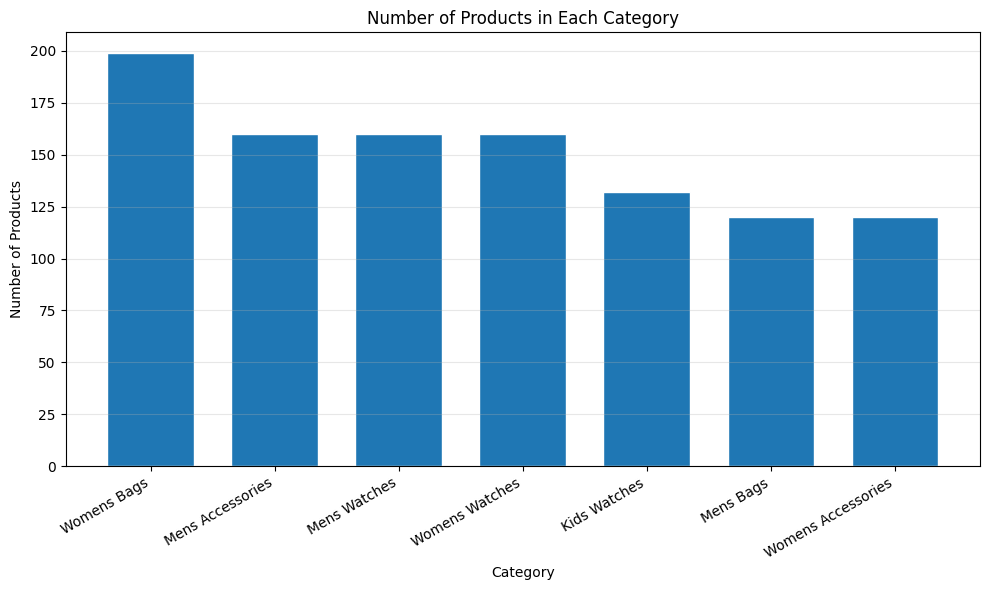

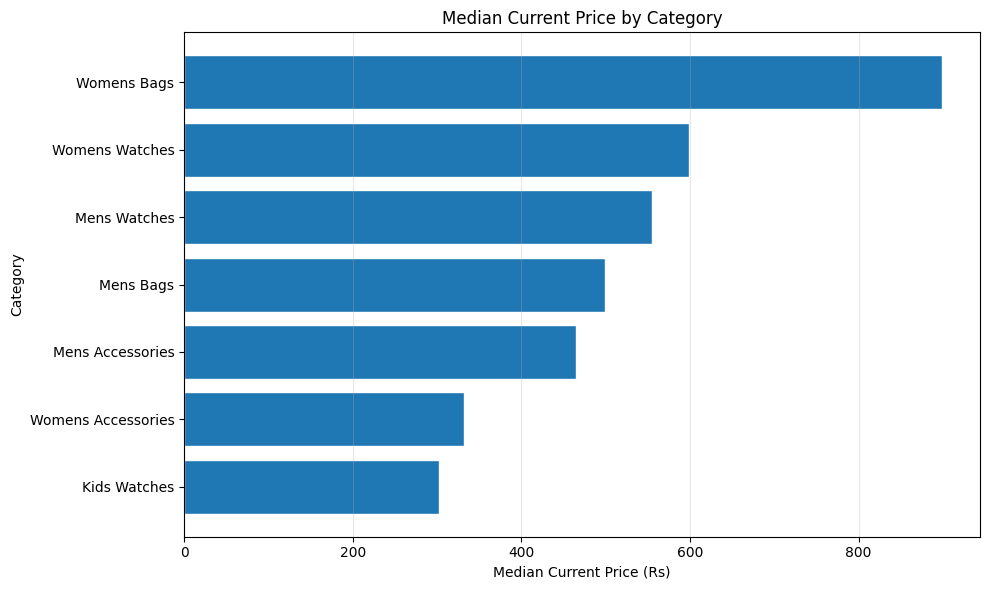

In [64]:
plot_category_overview(CLEANED_FILE)

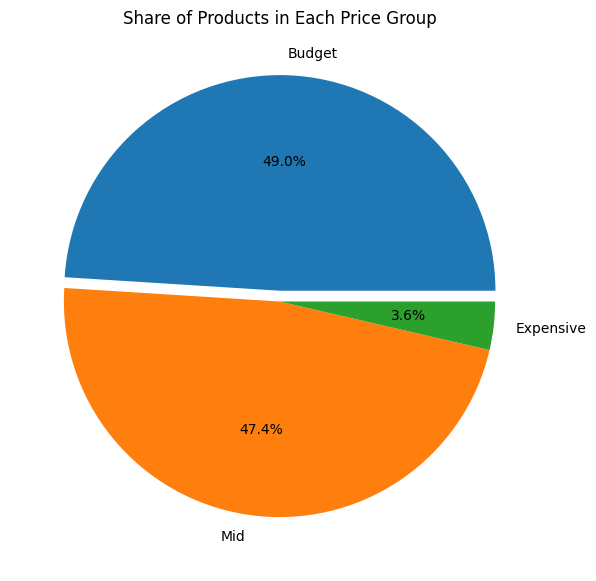

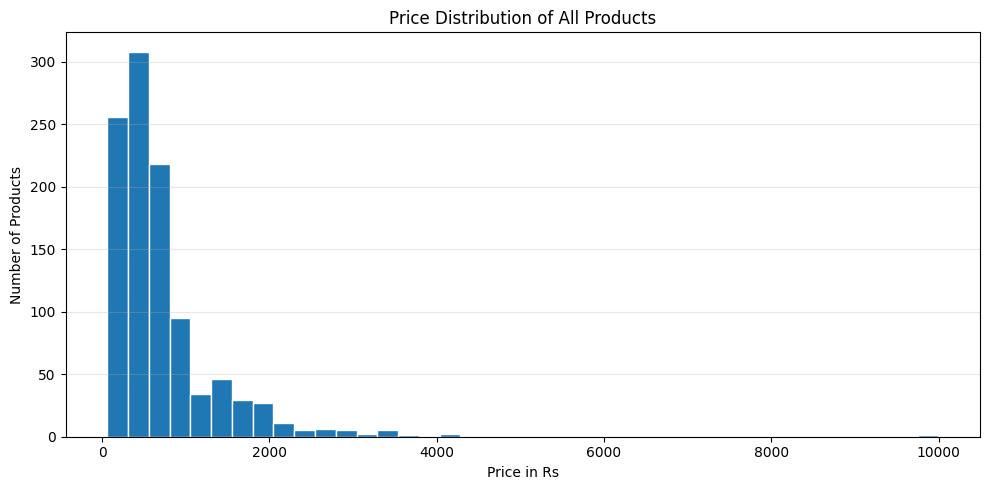

In [65]:
plot_price_distribution(CLEANED_FILE)

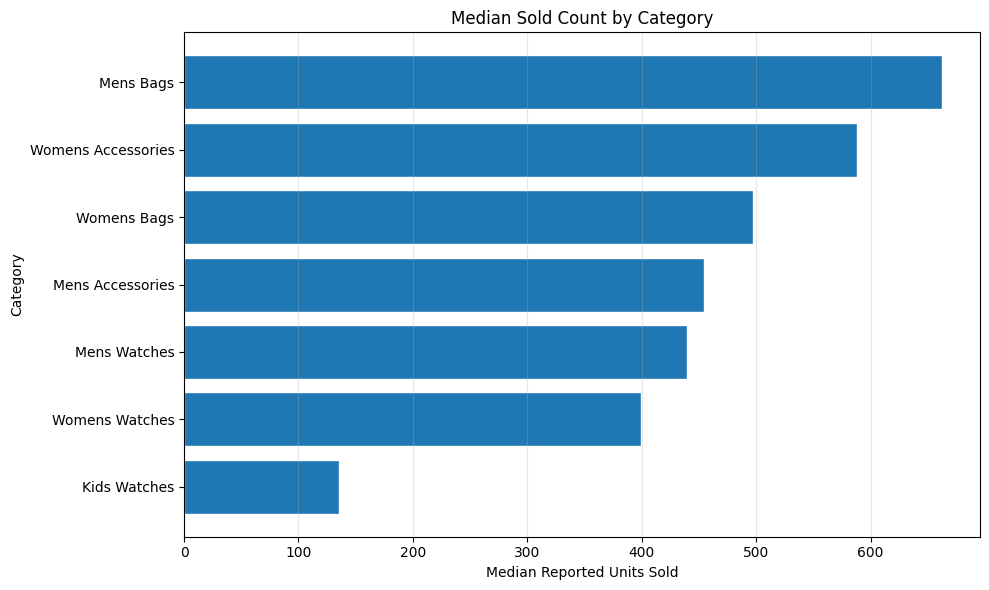

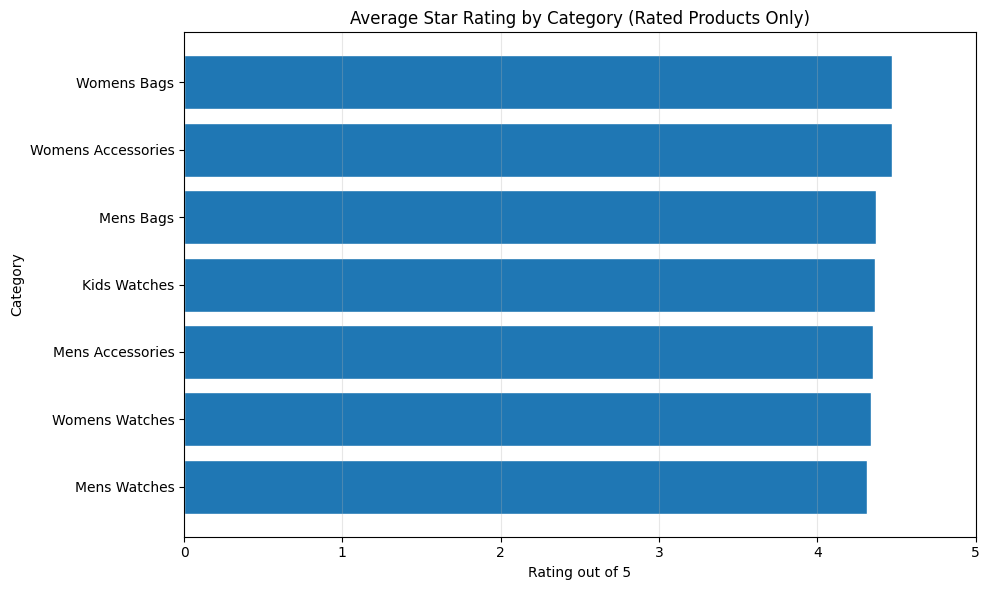

In [66]:
plot_sales_and_ratings(CLEANED_FILE)

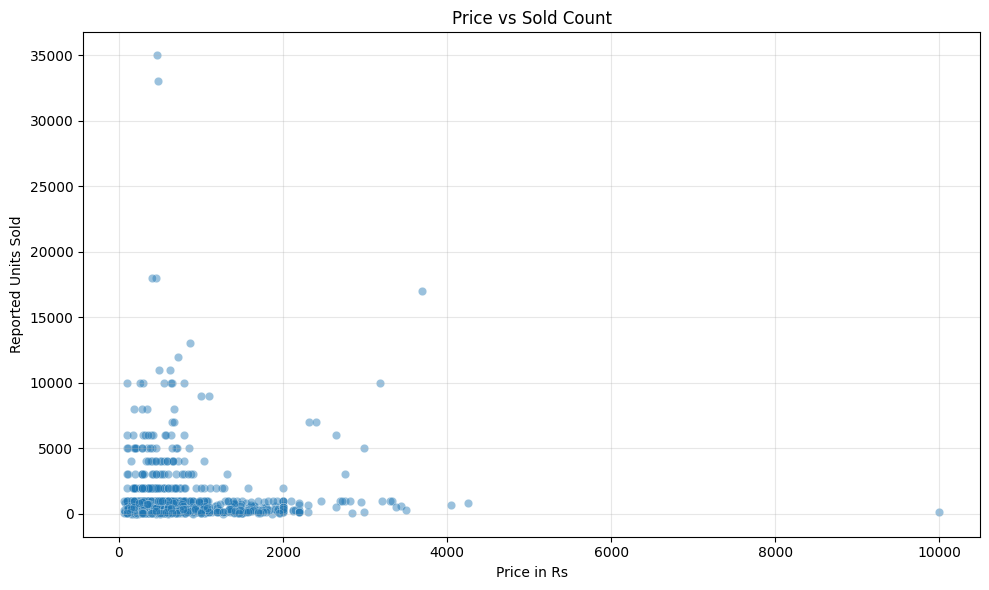

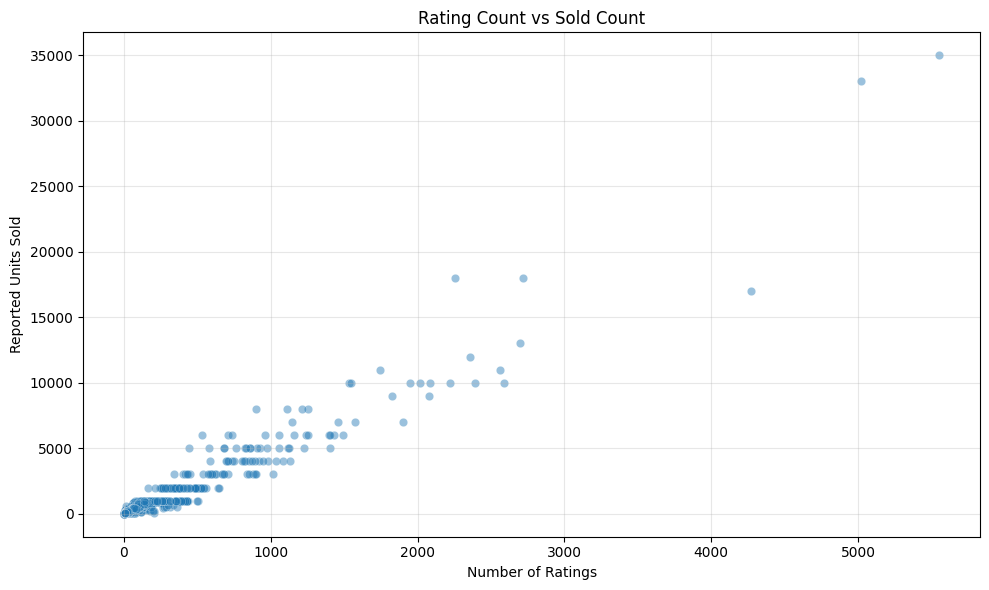

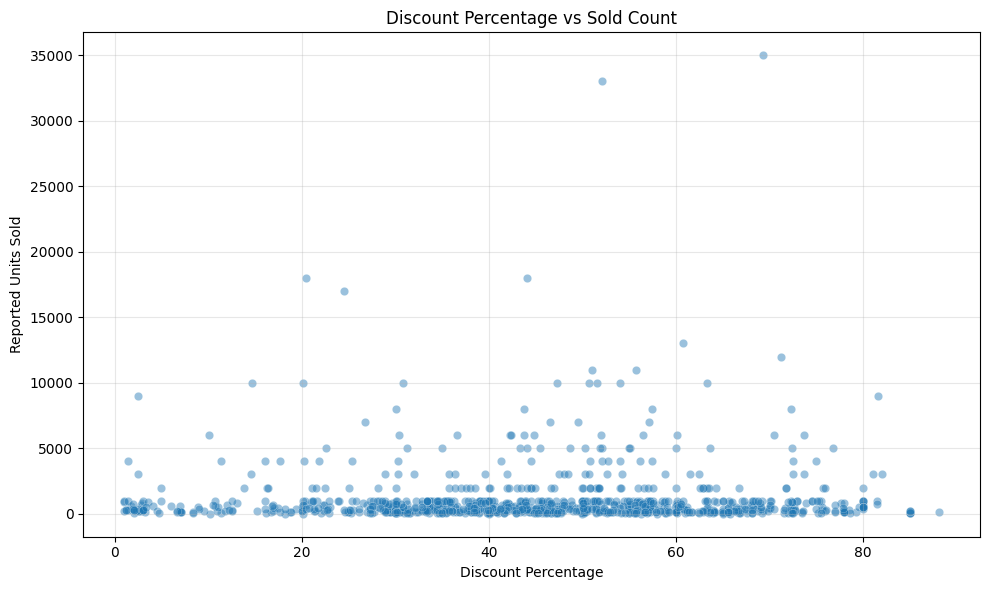

Correlations shown by the relationship plots:
Current Price -> -0.001
Rating Count -> 0.964
Discount % -> 0.028


In [67]:
visual_correlations = plot_relationships(CLEANED_FILE)
print("Correlations shown by the relationship plots:")
for variable, corr in visual_correlations.items():
    print(variable, "->", round(corr, 3))

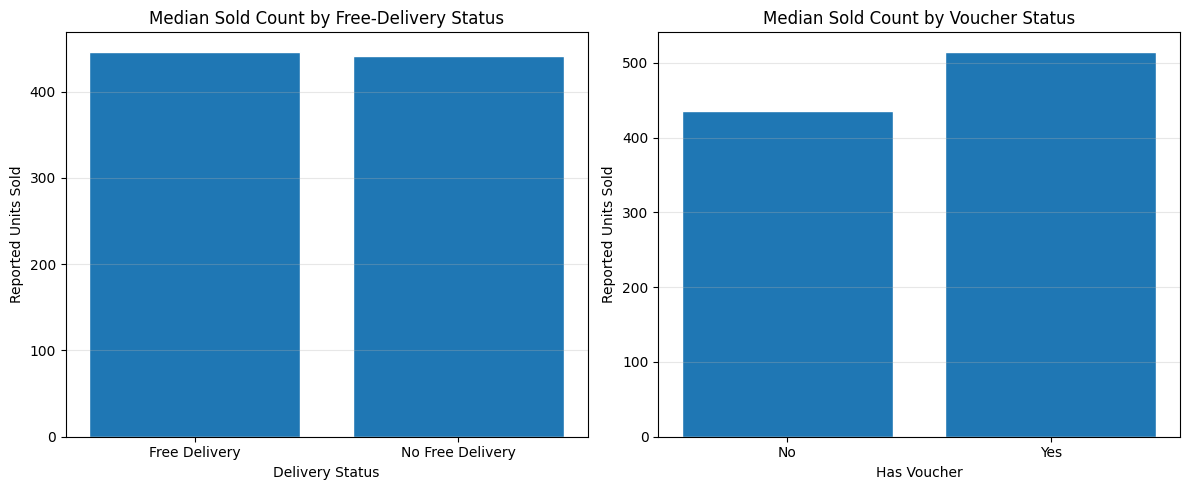

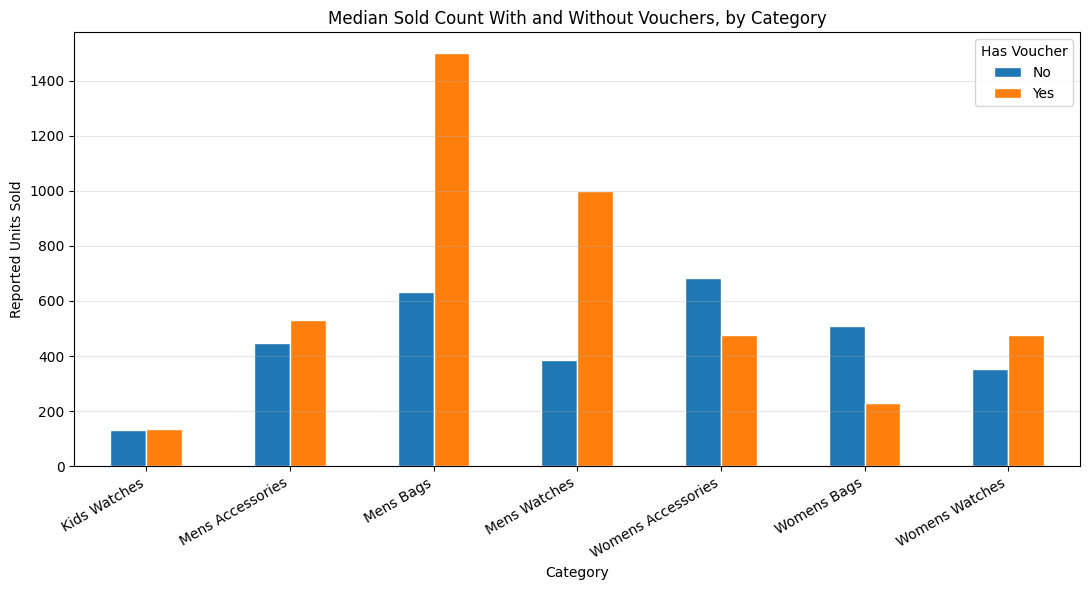

Number of records in each category/voucher group:


Has Voucher,No,Yes
Category,,
Kids Watches,125,7
Mens Accessories,147,13
Mens Bags,112,8
Mens Watches,124,36
Womens Accessories,94,26
Womens Bags,182,17
Womens Watches,112,48


In [68]:
voucher_group_sizes = plot_promotion_comparisons(CLEANED_FILE)
print("Number of records in each category/voucher group:")
display(voucher_group_sizes)

# 9. Findings, limitations and conclusion

The final module computes the findings from the datasource instead of hard-coding analytical results.

In [69]:
findings, limitations = generate_findings(SOURCE_FILE, CLEANED_FILE)

print("MAJOR FINDINGS")
for key, value in findings.items():
    if isinstance(value, float):
        print(f"{key}: {value:.3f}")
    else:
        print(f"{key}: {value}")

print("\nLIMITATIONS")
for number, item in enumerate(limitations, start=1):
    print(f"{number}. {item}")

MAJOR FINDINGS
raw_rows: 1078
unique_product_rows: 1051
median_price: 525.000
mean_price: 705.680
highest_median_price_category: Womens Bags
highest_median_price: 899.000
highest_median_sold_category: Mens Bags
highest_median_sold: 662.500
lowest_median_sold_category: Kids Watches
lowest_median_sold: 135.000
price_sold_correlation: -0.001
rating_sold_correlation: 0.095
rating_count_sold_correlation: 0.964
discount_sold_correlation: 0.028

LIMITATIONS
1. The dataset is a snapshot rather than a time series, so it cannot show changes over time.
2. Sold Count is a marketplace-reported field and some values are rounded, for example 6K Sold.
3. Correlation describes association, not causation.
4. The dataset contains selected product categories, so conclusions should not be generalized to all Daraz products.
5. Price groups are analyst-defined thresholds used for this project, not official Daraz categories.


## Final interpretation

- The raw datasource contains **1,078 rows**, while product-link deduplication leaves **1,051 unique product-link records**.
- The cleaned median current price is **Rs 525**, while the mean is about **Rs 705.68**, which supports using medians for skewed price comparisons.
- **Womens Bags** have the highest category median price (**Rs 899**).
- **Mens Bags** have the highest median reported sold count (**662.5**), while **Kids Watches** have the lowest (**135**).
- Price and discount percentage have almost no linear relationship with reported sold count in this dataset.
- Rating Count has a very strong positive association with Sold Count (about **0.964**), but this should not be interpreted as one causing the other.
- Voucher and delivery comparisons are descriptive associations; the dataset is observational and does not support causal claims.

## Modular-programming conclusion

The final notebook is the **orchestrator**. The actual logic is separated into reusable `.py` files and imported into the analysis. Concepts are visible, modules cooperate with one another, and all calculations come from the same real datasource.